# Feature Engineering

Scope: Feature engineering in the WESAD protocol.

Input: Tables generated by notebook 02, frozen configuration.

Output and saved artifacts: `features/chest_features`, `wrist_features`, `fused_features`, and `feature_names.json` (under the configured output root; real `.parquet`, synthetic `.csv`).

Dependencies: Environment from `requirements.txt`, `src/` modules; setup dependencies only in notebook 00.

Manual checks: Read `README.md`, `PROTOCOL.md`, and the corresponding row in `FILE_GUIDE.md`; do not interpret the smoke test as a WESAD result. No precompiled output.


In [1]:
from pathlib import Path
import os, sys
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / 'configs/config.yaml').is_file() and (p / 'src').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Start Jupyter inside the project folder; no machine-specific path is required')
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.config import load, setup, smoke_config
from src import workflow as w
SYNTHETIC = os.environ.get('WESAD_SYNTHETIC', '0') == '1'
c = load()
if SYNTHETIC: c = smoke_config(c)

# Reuse saved protocol instead of silently resetting extraction settings.
if not SYNTHETIC:
    import copy, json
    from src.config import fingerprint
    protocol_file = w.root(c) / 'protocol_lock.json'
    if protocol_file.is_file():
        from src.provenance import verify_lock
        saved_protocol = verify_lock(protocol_file)
        frozen = saved_protocol['config']
        if fingerprint(frozen) != saved_protocol['config_sha256']:
            raise ValueError('Saved protocol hash mismatch')
        c = copy.deepcopy(frozen)

setup(c)
print('Data mode:', 'SYNTHETIC EXECUTION ONLY' if SYNTHETIC else 'REAL WESAD')


Data mode: REAL WESAD


In [2]:
from pathlib import Path
from src.config import setup
from src.features import save_tables
from src.fusion import comparison_tables

raw_dir = Path(c["dataset"]["raw_dir"])
if not raw_dir.is_absolute():
    raw_dir = ROOT / raw_dir

c["dataset"]["raw_dir"] = str(raw_dir.resolve())
c["dataset"]["trusted_pickle"] = True  # Solo file ufficiali WESAD.

setup(c)

feature_dir = w.root(c) / "features"
fmt = c["output"]["feature_format"]
required_files = [
    feature_dir / f"{site}_features.{fmt}"
    for site in ("chest", "wrist")
]

if not all(path.is_file() for path in required_files):
    print("Feature mancanti: avvio estrazione e controllo qualità.")

    if SYNTHETIC:
        from src.synthetic import make_records
        records = make_records(seed=c["splits"]["seed"])
    else:
        records = w.load_records(c)

    tables, qc = w.feature_stage(records, c)
else:
    tables = w.load_tables(c)
    print(f"Feature caricate da: {feature_dir.resolve()}")

saved = save_tables(tables, c)

for site, frame in saved.items():
    duplicates = frame["window_id"].duplicated().sum()
    print(site, frame.shape, "duplicates:", duplicates)
    assert duplicates == 0, f"Finestre duplicate in {site}"
    assert set(frame["label"]) <= {1, 2, 3}, f"Label inattese in {site}"

print("Feature disponibili per le analisi successive.")


Feature mancanti: avvio estrazione e controllo qualità.
chest (1042, 33) duplicates: 0
wrist (1042, 26) duplicates: 0
fused (1005, 52) duplicates: 0
Feature disponibili per le analisi successive.


### Exploratory signal quality control

The heatmap shows, for each subject and channel, the fraction of windows excluded by quality checks. Exclusions are generally limited and concentrated primarily in the wrist BVP, with a higher incidence in subject 15. This suggests investigating the causes of the exclusions and their potential imbalance across conditions.

The ECG plot displays the first 60 seconds of the first loaded subject. Repeated peaks, an initial transient, and amplitude variations are visible. The Power Spectral Density (PSD), estimated using Welch's method, describes the distribution of signal power across frequencies. Inspection of this single segment does not allow for an evaluation of the quality of the entire recording.

Overall, the results support proceeding with the analysis. Passing the implemented checks does not guarantee the absence of artifacts and does not independently prove synchronization between sensors. The figures do not yet provide information on classification performance.

### ECG e densità spettrale di potenza

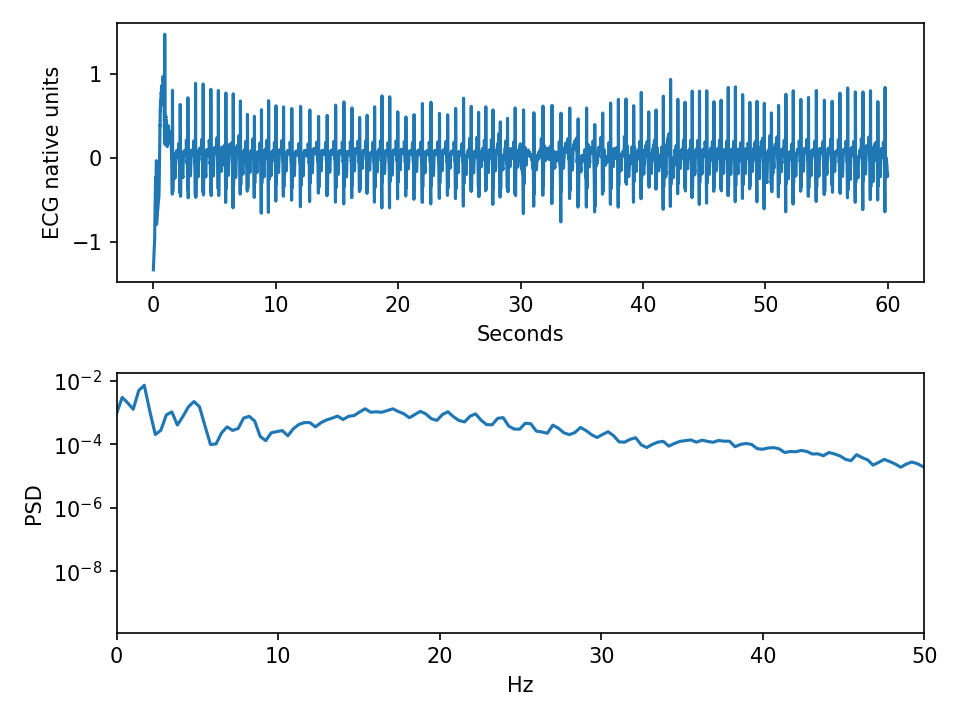

### Frazione di finestre escluse per soggetto e canale

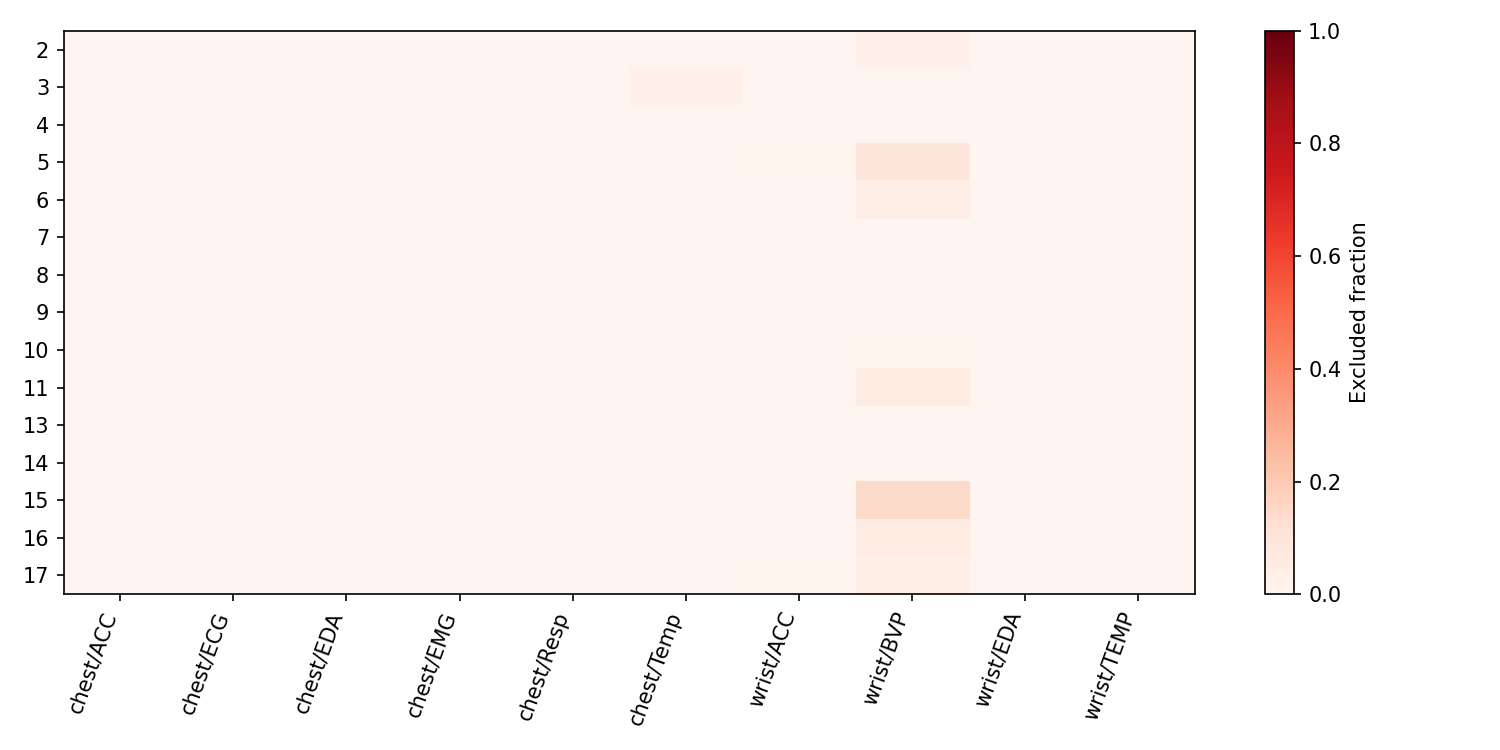

In [3]:
from pathlib import Path
from IPython.display import display, Image, Markdown

figures_dir = Path(w.root(c)) / "figures"

figures = {
    "ECG e densità spettrale di potenza": "signal_psd_example.png",
    "Frazione di finestre escluse per soggetto e canale": "qc_heatmap.png",
}

for title, filename in figures.items():
    path = figures_dir / filename
    display(Markdown(f"### {title}"))
    if path.is_file():
        display(Image(filename=str(path), width=1100))
    else:
        print(f"Figura non trovata: {path.resolve()}")

In [4]:
import pandas as pd
from IPython.display import display

qc_file = Path(w.root(c)) / "qc" / "signal_qc.csv"

if not qc_file.is_file():
    print(f"File QC non trovato: {qc_file.resolve()}")
else:
    qc_explore = pd.read_csv(qc_file)

    # Converte esplicitamente i valori letti dal CSV.
    valid_text = qc_explore["valid"].astype(str).str.strip().str.lower()
    if not valid_text.isin(["true", "false"]).all():
        raise ValueError("La colonna 'valid' contiene valori inattesi.")

    qc_explore["excluded"] = valid_text.eq("false")

    summary = (
        qc_explore.groupby(["site", "channel"])
        .agg(
            finestre_valutate=("excluded", "size"),
            finestre_escluse=("excluded", "sum"),
            percentuale_esclusa=("excluded", "mean"),
        )
        .reset_index()
    )
    summary["percentuale_esclusa"] *= 100

    display(
        summary.sort_values("percentuale_esclusa", ascending=False)
        .style.format({"percentuale_esclusa": "{:.2f}%"})
        .hide(axis="index")
    )

    by_subject = qc_explore.pivot_table(
        index="subject_id",
        columns=["site", "channel"],
        values="excluded",
        aggfunc="mean",
    ) * 100

    display(Markdown("### Percentuale di esclusione per soggetto e canale"))
    display(by_subject.style.format("{:.2f}%", na_rep="N/D"))

site,channel,finestre_valutate,finestre_escluse,percentuale_esclusa
wrist,BVP,1042,33,3.17%
chest,Temp,1042,2,0.19%
wrist,ACC,1042,2,0.19%
chest,ACC,1042,0,0.00%
chest,ECG,1042,0,0.00%
chest,EDA,1042,0,0.00%
chest,Resp,1042,0,0.00%
chest,EMG,1042,0,0.00%
wrist,EDA,1042,0,0.00%
wrist,TEMP,1042,0,0.00%


### Percentuale di esclusione per soggetto e canale

### Quality control results

A total of 1042 windows were evaluated for each channel. Wrist BVP exhibits the highest exclusion rate, with 33 windows excluded (3.17%). Chest temperature and the wrist accelerometer show 2 exclusions each (0.19%), while all other channels fully pass the implemented checks.

The overall limited exclusions support proceeding with the analysis without modifying the quality thresholds at this stage. However, passing the checks does not imply the absence of artifacts.

Prior to modeling, the distribution of exclusions per subject and condition, their underlying causes, and the count of effectively usable windows for chest, wrist, and fusion will be verified. The windows are partially overlapping, and their count does not represent the number of statistically independent observations.

In [5]:
import pandas as pd
from IPython.display import display
from src.fusion import comparison_tables
tables=w.load_tables(c)
rows=[]
for site,frame in tables.items():
    for (sid,label),g in frame.groupby(['subject_id','label']):
        rows.append(dict(site=site,subject_id=sid,label=label,candidate=len(g),valid=int(g.valid.sum())))
window_counts=pd.DataFrame(rows)
window_counts['excluded_percent']=100*(1-window_counts.valid/window_counts.candidate)
display(window_counts)
window_counts.to_csv(w.root(c)/'qc/window_counts_subject_class_modality.csv',index=False)
exclusion=window_counts.groupby(['site','label'])[['candidate','valid']].sum()
exclusion['excluded_percent']=100*(1-exclusion.valid/exclusion.candidate)
display(exclusion)
exclusion.to_csv(w.root(c)/'qc/exclusion_by_class_modality.csv')
common=comparison_tables(tables,True)['early_fusion']
balance=common.groupby(['subject_id','label']).size().unstack(fill_value=0)
display(balance)
balance.to_csv(w.root(c)/'qc/common_windows_subject_class.csv')
overall=common.groupby('label').size().rename('n_windows').to_frame()
overall['percent']=100*overall.n_windows/overall.n_windows.sum()
display(overall)
overall.to_csv(w.root(c)/'qc/common_class_balance.csv')
print('Conteggi di finestre sovrapposte: non osservazioni indipendenti.')


,site,subject_id,label,candidate,valid,excluded_percent
0,chest,2,1,37,37,0.000000
1,chest,2,2,19,19,0.000000
2,chest,2,3,11,11,0.000000
3,chest,3,1,37,37,0.000000
4,chest,3,2,20,18,10.000000
...,...,...,...,...,...,...
85,wrist,16,2,21,19,9.523810
86,wrist,16,3,11,9,18.181818
87,wrist,17,1,38,37,2.631579
88,wrist,17,2,23,21,8.695652


candidate  valid  excluded_percent
site  label                                    
chest 1            566    566          0.000000
      2            311    309          0.643087
      3            165    165          0.000000
wrist 1            566    550          2.826855
      2            311    297          4.501608
      3            165    160          3.030303

label,1,2,3
subject_id,,,
2,37,17,11
3,37,18,11
4,37,20,11
5,32,20,10
6,38,18,10
7,38,20,11
8,37,21,11
9,38,20,11
10,37,23,11


,n_windows,percent
label,,
1,550,54.726368
2,295,29.353234
3,160,15.920398


Conteggi di finestre sovrapposte: non osservazioni indipendenti.
